# Modelos

Seguimos desde el notebook de datos. Ahi vimos que el bloque de no-detecciones y los colores WISE no aportan, y que el periodo hay que pasarlo a log porque si no aplasta al resto.

Acá partimos train / val / test **antes** de imputar y escalar. Despues entrenamos un autoencoder, un GMM en el cuello de botella, y una pasada de MCDSVDD.

In [2]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# jupyter a veces parte en notebooks/ y a veces en la raiz
aqui = Path.cwd().resolve()
raiz = aqui if (aqui / "src").exists() else aqui.parent
if str(raiz / "src") not in sys.path:
    sys.path.insert(0, str(raiz / "src"))

from ic_project.modelos import asignar_mcdsvdd, entrenar_autoencoder, entrenar_mcdsvdd, latente
from ic_project.preprocesamiento import preparar_conjuntos

colores = {
    "CEP": "steelblue",
    "DSCT": "chocolate",
    "EB": "mediumseagreen",
    "LPV": "indianred",
    "RRL": "magenta",
}

In [3]:
ruta_datos = raiz / "data" / "raw"

df_features = pd.read_parquet(ruta_datos / "features.parquet")
df_oids = pd.read_parquet(ruta_datos / "oids.parquet")

print("features", df_features.shape)
print("oids    ", df_oids.shape)

X = df_features.drop(columns="oid")
oids = df_features["oid"].reset_index(drop=True)
labels = df_features[["oid"]].merge(df_oids, on="oid", how="left")["alerceclass"].reset_index(drop=True)

mask = labels.notna()
X = X.loc[mask].reset_index(drop=True)
oids = oids.loc[mask].reset_index(drop=True)
labels = labels.loc[mask].reset_index(drop=True)

print(labels.value_counts())

features (8419, 179)
oids     (9829, 2)
alerceclass
EB      2689
RRL     2652
LPV     1374
CEP     1172
DSCT     532
Name: count, dtype: int64


### Particion

70% train, 15% val, 15% test, estratificado por clase. La mediana, el recorte y la escala se calculan solo con train. Si se calculan con todo el conjunto, el test se filtra al modelo.

In [4]:
conjuntos, prep, descartadas = preparar_conjuntos(X, labels, oids)

print("descartadas:", len(descartadas))
print(
    "train / val / test:",
    len(conjuntos["y_train"]),
    len(conjuntos["y_val"]),
    len(conjuntos["y_test"]),
)
print("features que entran al modelo:", conjuntos["x_train"].shape[1])
print(conjuntos["y_train"].value_counts())

descartadas: 20
train / val / test: 5893 1263 1263
features que entran al modelo: 158
alerceclass
EB      1883
RRL     1856
LPV      962
CEP      820
DSCT     372
Name: count, dtype: int64


### Autoencoder

Comprime las features a 8 numeros y trata de reconstruirlas. Esos 8 son el cuello de botella. Con 2 se pierde harto, asi que el grafico de mas abajo es un UMAP del test, igual que en el notebook de datos. El UMAP es solo para mirar, no entra al GMM.

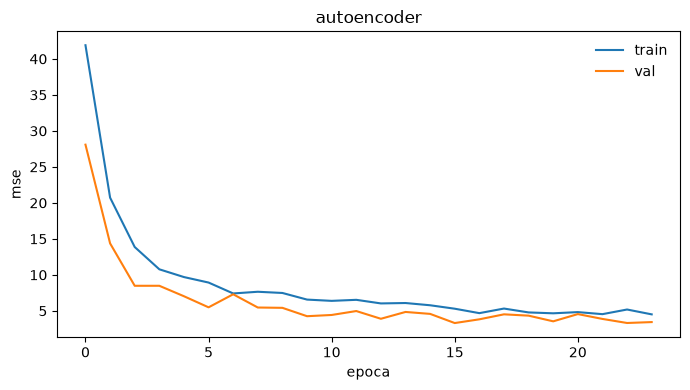

epocas corridas: 24
mejor mse val: 3.3029


In [5]:
ae, hist = entrenar_autoencoder(
    conjuntos["x_train"],
    conjuntos["x_val"],
    z_dim=8,
    n_epocas=40,
    semilla=42,
)

plt.figure(figsize=(7, 4))
plt.plot(hist.train, label="train")
plt.plot(hist.val, label="val")
plt.xlabel("epoca")
plt.ylabel("mse")
plt.legend(frameon=False)
plt.title("autoencoder")
plt.tight_layout()
plt.show()

print("epocas corridas:", len(hist.val))
print("mejor mse val:", round(min(hist.val), 4))

c:\Users\tomas\Desktop\TRABAJO INTELIGENCIA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\tomas\Desktop\TRABAJO INTELIGENCIA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


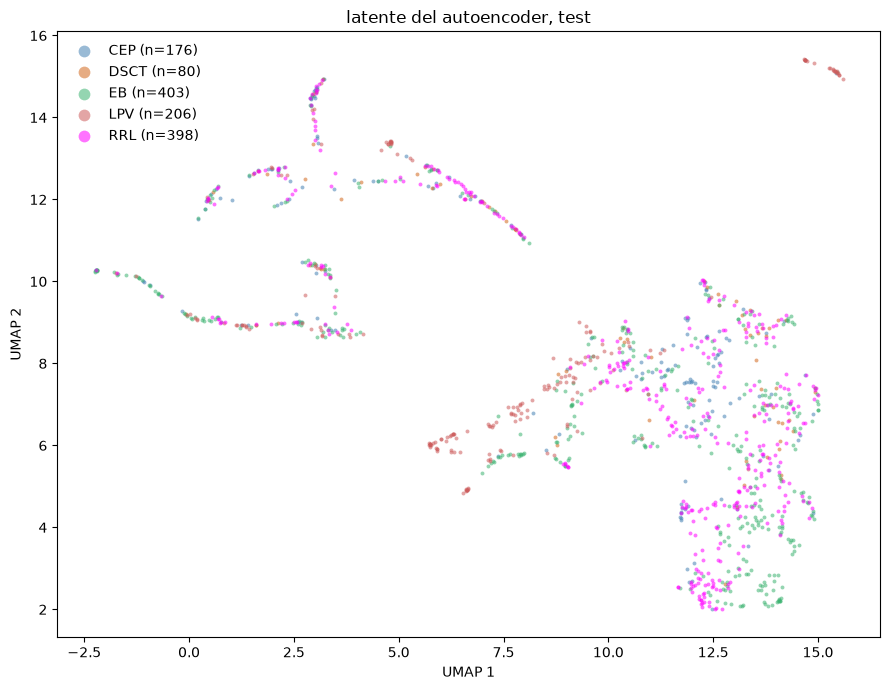

In [6]:
import umap

z_train = latente(ae, conjuntos["x_train"])
z_test = latente(ae, conjuntos["x_test"])

# UMAP solo del test, para dibujar
emb = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42).fit_transform(z_test)

clases_test = conjuntos["y_test"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 7))
for clase, color in colores.items():
    m = clases_test == clase
    ax.scatter(emb[m, 0], emb[m, 1], s=8, alpha=0.55, c=color, label=f"{clase} (n={m.sum()})", linewidths=0)

ax.legend(markerscale=3, frameon=False)
ax.set_title("latente del autoencoder, test")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
plt.tight_layout()
plt.show()

Las clases no quedan separadas. LPV se corre un poco, el resto va mezclado. Por eso un clustering que no ve la etiqueta no tiene de donde recuperar las 5 clases.

### GMM

Mezcla de gaussianas con 5 componentes, ajustada **solo** con el latente de train. Las metricas son del test.

Silhouette mas alto = grupos mas separados. Davies-Bouldin mas bajo = mejor. Esas dos las calculamos con los clusters del GMM y tambien con las clases reales (no miden lo mismo). ARI y NMI comparan clusters contra clase: 0 es azar, 1 es que coinciden.

In [7]:
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture


def medir(z, pred, real):
    print("silhouette grupos ", round(silhouette_score(z, pred), 3))
    print("silhouette clases ", round(silhouette_score(z, real), 3))
    print("davies-bouldin grupos", round(davies_bouldin_score(z, pred), 3))
    print("davies-bouldin clases", round(davies_bouldin_score(z, real), 3))
    print("ARI", round(adjusted_rand_score(real, pred), 3))
    print("NMI", round(normalized_mutual_info_score(real, pred), 3))


gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42, n_init=5)
gmm.fit(z_train)
pred_gmm = gmm.predict(z_test)

print("GMM en test")
medir(z_test, pred_gmm, clases_test)
print()
display(pd.crosstab(clases_test, pred_gmm, rownames=["clase"], colnames=["cluster"]))

GMM en test
silhouette grupos  0.166
silhouette clases  -0.204
davies-bouldin grupos 2.064
davies-bouldin clases 6.359
ARI 0.102
NMI 0.134



cluster,0,1,2,3,4
clase,,,,,
CEP,88,15,22,37,14
DSCT,40,3,14,23,0
EB,197,55,25,104,22
LPV,7,13,7,70,109
RRL,252,21,33,89,3


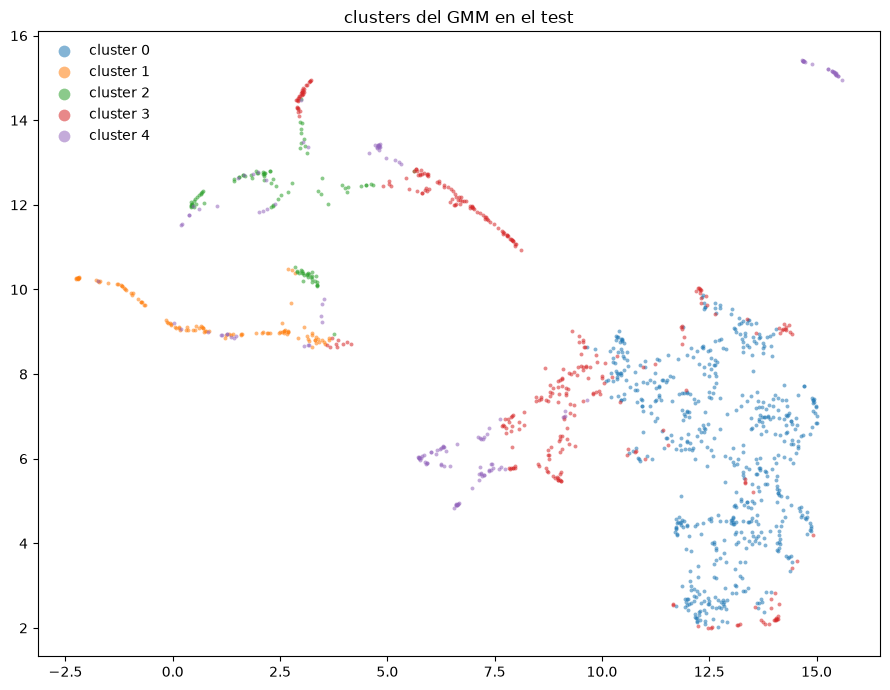

In [8]:
# mismos ejes que el UMAP de arriba, ahora pintado por cluster
fig, ax = plt.subplots(figsize=(9, 7))
for k in np.unique(pred_gmm):
    m = pred_gmm == k
    ax.scatter(emb[m, 0], emb[m, 1], s=8, alpha=0.55, label=f"cluster {k}", linewidths=0)
ax.legend(markerscale=3, frameon=False)
ax.set_title("clusters del GMM en el test")
plt.tight_layout()
plt.show()

El GMM no ve la clase. En la tabla se nota: un componente se lleva a CEP, EB, RRL y DSCT juntos. LPV es la que mas cae en otro lado. El ARI queda cerca de 0, o sea casi no recupera las etiquetas. Calza con el UMAP de arriba.

### MCDSVDD

Este si usa la clase. Parte del encoder que ya entrenamos, calcula un centro por clase y acerca cada objeto al centro de la suya. En test lo asignamos al centro mas cercano.

DSCT tiene harto menos objetos que EB y RRL, y esta version no balancea, asi que puede salir mal. Para el meeting alcanza con ver donde falla.

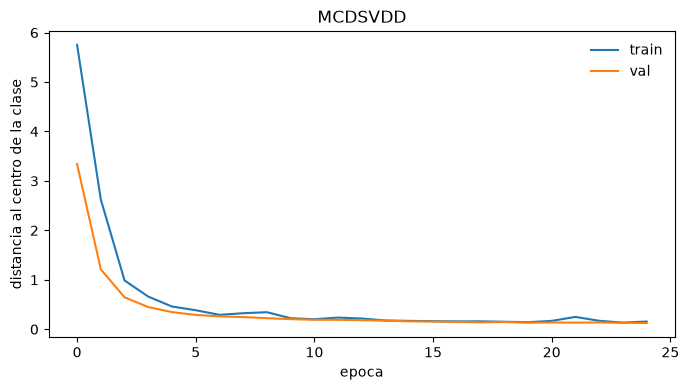

epocas: 25


In [9]:
clases = sorted(conjuntos["y_train"].unique())
mapa = {c: i for i, c in enumerate(clases)}

y_train_i = conjuntos["y_train"].map(mapa).to_numpy()
y_val_i = conjuntos["y_val"].map(mapa).to_numpy()

mcd, hist_mcd = entrenar_mcdsvdd(
    conjuntos["x_train"],
    y_train_i,
    conjuntos["x_val"],
    y_val_i,
    autoencoder=ae,
    z_dim=8,
    n_epocas=25,
    semilla=42,
)

plt.figure(figsize=(7, 4))
plt.plot(hist_mcd.train, label="train")
plt.plot(hist_mcd.val, label="val")
plt.xlabel("epoca")
plt.ylabel("distancia al centro de la clase")
plt.legend(frameon=False)
plt.title("MCDSVDD")
plt.tight_layout()
plt.show()

print("epocas:", len(hist_mcd.val))

c:\Users\tomas\Desktop\TRABAJO INTELIGENCIA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


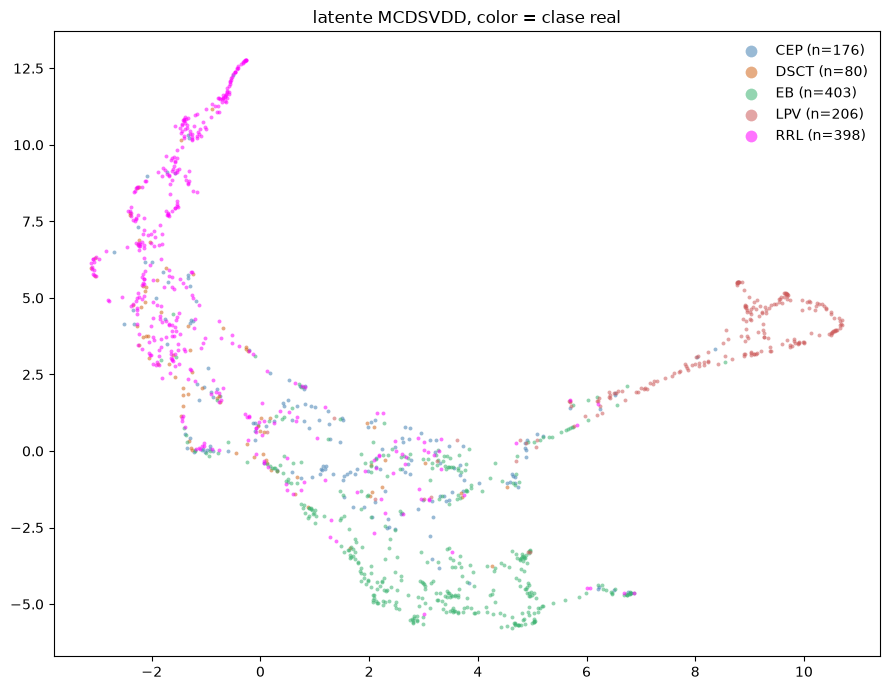

MCDSVDD en test
silhouette grupos  0.207
silhouette clases  0.154
davies-bouldin grupos 0.827
davies-bouldin clases 1.891
ARI 0.334
NMI 0.441



centro,CEP,DSCT,EB,LPV,RRL
clase,,,,,
CEP,131,0,16,4,25
DSCT,49,0,2,0,29
EB,166,0,234,2,1
LPV,25,0,10,171,0
RRL,129,1,6,0,262


In [10]:
z_mcd = latente(mcd, conjuntos["x_test"])
pred_i = asignar_mcdsvdd(mcd, conjuntos["x_test"])
pred_mcd = np.array(clases)[pred_i]

emb_mcd = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42).fit_transform(z_mcd)

fig, ax = plt.subplots(figsize=(9, 7))
for clase, color in colores.items():
    m = clases_test == clase
    ax.scatter(emb_mcd[m, 0], emb_mcd[m, 1], s=8, alpha=0.55, c=color, label=f"{clase} (n={m.sum()})", linewidths=0)
ax.legend(markerscale=3, frameon=False)
ax.set_title("latente MCDSVDD, color = clase real")
plt.tight_layout()
plt.show()

print("MCDSVDD en test")
medir(z_mcd, pred_mcd, clases_test)
print()
display(pd.crosstab(clases_test, pred_mcd, rownames=["clase"], colnames=["centro"]))

Mejora respecto al GMM (ARI y NMI mas altos) porque ahora el modelo si vio la clase al entrenar. En la diagonal de la tabla estan los que caen en su propio centro. DSCT queda practicamente en cero: se va a CEP o a RRL.

### Que features importan

Random forest solo con train, con peso para las clases chicas. No lo usamos para filtrar el autoencoder, es para ver si el periodo queda arriba.

Multiband_period_g_r    0.095378
Period_band_g           0.083641
Period_band_r           0.044945
g-r_mean_g_r            0.039801
GP_DRW_tau_r            0.039202
g-r_max_g_r             0.032421
g-r_mean_corr_g_r       0.031621
g-r_max_corr_g_r        0.031475
IAR_phi_r               0.028309
Autocor_length_r        0.026058
GP_DRW_tau_g            0.021868
IAR_phi_g               0.016610
dtype: float64


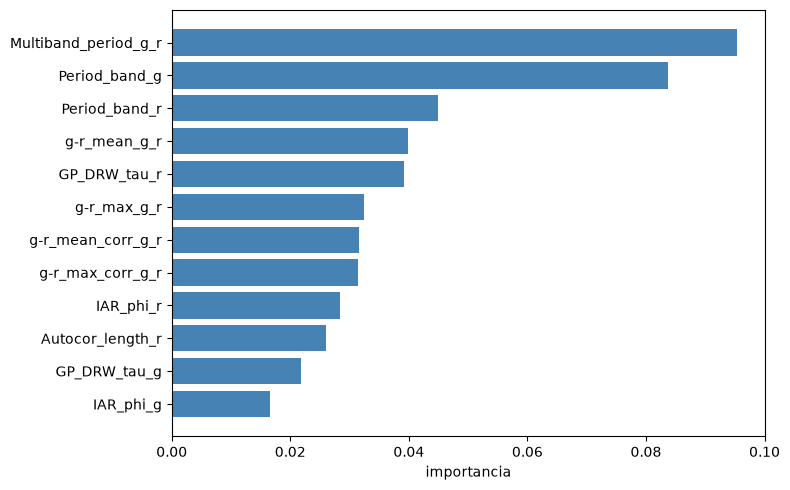

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=16,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
rf.fit(conjuntos["x_train"], conjuntos["y_train"])

imp = pd.Series(rf.feature_importances_, index=prep.columnas_).sort_values(ascending=False)
print(imp.head(12))

top = imp.head(12)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color="steelblue")
plt.xlabel("importancia")
plt.tight_layout()
plt.show()

Las primeras son periodos (multibanda, banda g, banda r) y despues el color g-r. Era lo que esperabamos: las clases viven en escalas de tiempo distintas.

Falta mirar las curvas de luz de los objetos mas cercanos a cada centro y de los que quedan afuera, y el experimento de sacar una clase del entrenamiento para ver si el modelo la marca como rara.